In [47]:
#Simple Pendulum: d^2 theta / dt^2 + g / L * sin theta = 0

import numpy as np
import matplotlib.pyplot as plt

#set length of the pendulum
L = 1

def f(theta, w):
    return w, - 9.8 / L * np.sin(theta)

#small angle approximation

def g(theta_small, u):
    return u, -9.8 / L * theta_small

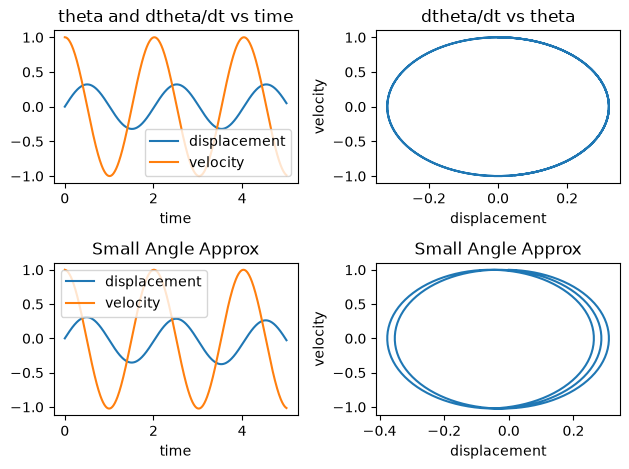

In [63]:
#using rk4

#using rk4 method

t0 = 0
tmax = 5

#set time-step
h = 0.01

#set initial conditions
theta0 = 0
w0 = 1

theta_small0 = 0
u0 = 1

time = [t0]
displacement = [theta0]
velocity = [w0]

displacement_small = [theta_small0]
velocity_small = [u0]

while t0 < tmax - 1e-12:
    k1theta, k1w = f(theta0, w0)
    k2theta, k2w = f(theta0 + h/2*k1theta, w0 + h/2*k1w)
    k3theta, k3w = f(theta0 + h/2*k2theta, w0 + h/2*k2w)
    k4theta, k4w = f(theta0 + h*k3theta, w0 + h*k3w)    
    w0 = w0 + h * (k1w + 2 * k2w + 2 * k3w + k4w) / 6  
    theta0 = theta0 + h * (k1theta + 2 * k2theta + 2 * k3theta + k4theta) / 6

    k1theta_small, k1u = g(theta0, u0)
    k2theta_small, k2u = g(theta0 + h/2*k1theta, u0 + h/2*k1w)
    k3theta_small, k3u = g(theta0 + h/2*k2theta, u0 + h/2*k2w)
    k4theta_small, k4u = g(theta0 + h*k3theta, u0 + h*k3w)    
    u0 = u0 + h * (k1u + 2 * k2u + 2 * k3u + k4u) / 6  
    theta_small0 = theta_small0 + h * (k1theta_small + 2 * k2theta_small + 2 * k3theta_small + k4theta_small) / 6
    
    t0 = t0 + h

    time.append(t0)
    displacement.append(theta0)
    velocity.append(w0)
    displacement_small.append(theta_small0)
    velocity_small.append(u0)

fig, ax = plt.subplots(2, 2)

ax[0, 0].plot(time, displacement)
ax[0, 0].plot(time, velocity)
ax[0, 0].set_title("theta and dtheta/dt vs time")
ax[0, 0].set_xlabel("time")
ax[0, 0].legend(["displacement", "velocity"])

ax[0, 1].plot(displacement, velocity)
ax[0, 1].set_title("dtheta/dt vs theta")
ax[0, 1].set_xlabel("displacement")
ax[0, 1].set_ylabel("velocity")

ax[1, 0].plot(time, displacement_small)
ax[1, 0].plot(time, velocity_small)
ax[1, 0].set_title("Small Angle Approx")
ax[1, 0].set_xlabel("time")
ax[1, 0].legend(["displacement", "velocity"])

ax[1, 1].plot(displacement_small, velocity_small)
ax[1, 1].set_title("Small Angle Approx")
ax[1, 1].set_xlabel("displacement")
ax[1, 1].set_ylabel("velocity")
plt.tight_layout()
plt.show()


In [66]:
#animation
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

x = L * np.sin(displacement)
y = - L * np.cos(displacement)
x_small = L * np.sin(displacement_small)
y_small = - L * np.cos(displacement_small)

fig, ax = plt.subplots(1, 2)

ax[0].set_xlim(-1.3 * L, 1.3 * L)
ax[0].set_ylim(-1.3 * L, 0.3 * L)
ax[0].set_title("Simple Pendulum")

ax[1].set_xlim(-1.3 * L, 1.3 * L)
ax[1].set_ylim(-1.3 * L, 0.3 * L)
ax[1].set_title("Under Small Approx")

#fixed pivot
ax[0].plot(0, 0, "ko", markersize=6)
ax[1].plot(0, 0, "ko", markersize=6)

#pendulum thread
thread1, = ax[0].plot([], [], "k-", linewidth=2)
thread2, = ax[1].plot([], [], "k-", linewidth=2)

#pendulum bob
bob1, = ax[0].plot([], [], "o", color="red", markersize=14)
bob2, = ax[1].plot([], [], "o", color="red", markersize=14)

#trace of the bob's path
trace1, = ax[0].plot([], [], "b--", alpha=0.5, linewidth=1)
trace2, = ax[1].plot([], [], "b--", alpha=0.5, linewidth=1)


def update(i):
    thread1.set_data([0, x[i]], [0, y[i]])
    bob1.set_data([x[i]], [y[i]])
    trace1.set_data(x[:i+1], y[:i+1])

    thread2.set_data([0, x_small[i]], [0, y_small[i]])
    bob2.set_data([x_small[i]], [y_small[i]])
    trace2.set_data(x_small[:i+1], y_small[:i+1])

    return thread1, bob1, trace1, thread2, bob2, trace2

ani = FuncAnimation(fig, update, frames=len(time), interval=20, blit=True, repeat=True)

plt.close(fig)
display(HTML(ani.to_jshtml()))